### With the use of a spring-powered launcher of spring coefficient 20 N/m, a ping-pong ball is launched into a cup 1.4 meters away (D = 0.092 m). During the launch, there is wind blowing in the same direction the ball is going at 9 m/s. What is the compression of the spring such that the ping-pong ball successfully makes it into the cup?

(Standard ping-pong ball size and mass: D = 0.04 m, 0.0027 kg)

In [11]:
# this code block imports necessary libraries. 
# numpy for assisting in working with values, 
# matplotlib for graphing
import numpy as np 
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import brentq

### How will the velocity v used in the drag force expression be obtained?

The expression for both linear and quadratic drag force requires you to take into consideration the relative velocity of the moving object through the fluid (in this case, the ping-pong ball through the air.) <br>

When considering drag in the x direction: $v_{x, relative} = v_{wind} - v_x$<br>
When considering drag in the y direction: $v_{y, relative} = v_{y}$. This is because the wind is only blowing in the x direction; therefore, there is no vertical component. 

### Is it expected that the drag will be linear, quadratic, or both? What is the Reynolds number for this scenerio?

Reynolds number:
$R = \frac{\rho \ v_{relative} \ D}{\xi}$ <br>
Where $\rho$ is the air density, v is the velocity, D is the object diameter, and $\xi$ is a constant dependant on the medium; for air, using the given values in  Taylor, it is 1.2.

R will change as the ball velocity changes, but in the case of the ping-pong ball, it will always be considerably above 1, meaning that only quadratic drag will have to be minded in this problem. 

$R = \frac{\rho \ v_{relative} \ D}{\xi} = \frac{(1.2 kg/m^3)(v)(0.04 m)}{(1.5e-5)} = 3200v$ <br>

The velocity will always be above 1.


In [25]:
# define parameters
k = 20.0 # N/m
m = 0.00273 # kg
D = 0.040 # m
g = 9.8 # m/s^2

cup_radius = 0.046 # m

vw0 = 9.0 # m/s
xi = 1.2 # (constant for linear drag coeff / quadratic drag coeff for air)
X = 1.4 # the separation; m
R = 0.046 # cup radius, m

beta, gamma = 1.6e-4, 0.25               # Taylor's drag constants (air, SI)
b, c = beta*D, gamma*D**2
nu = 1.5e-5 


### Explain the drag coefficients used in this problem.

$\xi$ was determined using the values of the linear and quadratic drag coefficient values of air; 1.6e-4 $\frac{Ns}{m^2}$ and 0.25 $\frac{Ns^2}{m^4}$ respectively.

In [33]:
v0 = dx*np.sqrt(k/m)
print("Re (wind speed)  =", D*vw0/nu)          # ~2e4
print("Re (launch speed)=", D*v0/nu)           # ~9e3
print("quad/lin ratio at 9 m/s =", c*9/b)      # ~560 -> quadratic dominates

Re (wind speed)  = 24000.0
Re (launch speed)= 8698.627528677087
quad/lin ratio at 9 m/s = 562.5


This code block has three functions:

`equations_of_motion`: This function returns the accelerations and velocities that the solver requires. Takes the time `t`; the state of the system (in this case, the ball) as `s`, as an array [x_position, y_position, x_velocity, y_velocity]; and the wind speed `vw` (which is initally declared above and will not change.) It finds the relative velocites of the ball and calls them `ux` and `uy`, finds the relative speed, then finds the drag using the relative speed. 

`hit_ground`: takes the time, system state, and velocity. When the ball is determined to go below the rim of the cup, `hit_ground.terminal` becomes true.

`fly`: (Why did Claude name it this?...) This function finds the initial velocity of the ball using $KE = 0.5kx^2$ and calls it `v0`, then creates a dictionary of parameters for the solver. `rtol` and `atol` are error tolerances, and the rest I don't quite understand, but would be interested to learn more about. 

`sol` does the integrating by passing the following to `solve_ivp`, a function in `scipy.integrate` that solves Initial Value Problems (hence, ivp): `equations_of_motion`; a range of time to integrate over ([0,10] being zero to ten seconds, a good range to guess the trajectory takes); creating the inital state; and then returning the events.


In [ ]:
def equations_of_motion(t, s, vw):
    x, y, vx, vy = s
    ux, uy = vx - vw, vy   # finds the relative velocity
    sp = np.hypot(ux, uy)  # velocity magnitude
    F = (b + c*sp)         # f = (b + c|v_rel|) v_rel
    return [vx, vy, -F*ux/m, -g - F*uy/m] # returns velocities and derivatives

# stop solving when the ball enters the cup (when y becomes negative)
def hit_ground(t, s, vw): return s[1]
hit_ground.terminal, hit_ground.direction = True, -1   # only on the way down

def fly(dx, vw=vw0, **kw):
    v0 = dx*np.sqrt(k/m)                 # (1/2)k dx^2 = (1/2) m v0^2
    opts = dict(rtol=1e-10, atol=1e-12, method="DOP853", dense_output=True)
    opts.update(kw)
    sol = solve_ivp(equations_of_motion, [0, 10], [0, 0, 0, v0], args=(vw,),
                    events=hit_ground, **opts)
    return sol.y_events[0][0][0], sol    # landing x, full solution


This code block has the "numerical solver", which finds the displacement `dx` in which the landing position equals `X`. It does that setting a range for what dx could be ([0.005, 0.1], because if it was smaller than 0.5 cm, the ball wouldn't make it; if it was larger than 0.1, the ball would be overshot, so it has to be in between); setting a precision tolerance (1e-12), and determines it by trying a bunch of possibilies with `fly `.

Once it finds something that works within that precision tolerance, it runs the `fly` function one last time to get a final answer.

In [20]:
# the "numerical solver"

dx = brentq(lambda d: fly(d)[0] - X, 0.005, 0.1, xtol=1e-12)
xland, sol = fly(dx)
print(f"Compression of spring = {dx*100:.3f} cm, Initial velocity of ball = {dx*np.sqrt(k/m):.3f} m/s, "
      f"Time ball was in air = {sol.t_events[0][0]:.3f} s, Distance ball travelled in x = {xland:.6f} m")


Compression of spring = 3.811 cm, Initial velocity of ball = 3.262 m/s, Time ball was in air = 0.588 s, Distance ball travelled in x = 1.400000 m


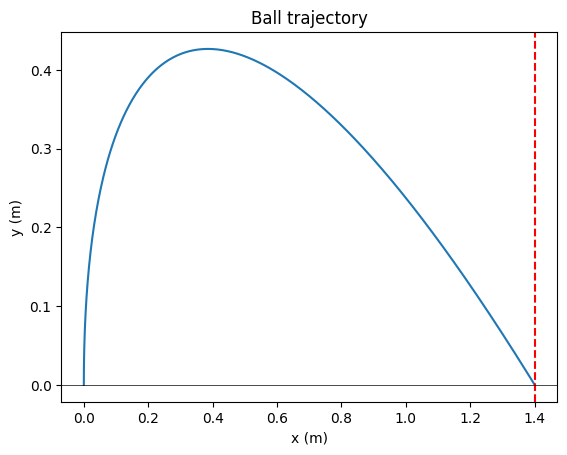

In [21]:
t = np.linspace(0, sol.t_events[0][0], 400)
x, y = sol.sol(t)[0], sol.sol(t)[1]
plt.plot(x, y); plt.axvline(X, ls="--", c="r")
plt.axhline(0, c="k", lw=.5)
plt.xlabel("x (m)"); plt.ylabel("y (m)"); plt.title("Ball trajectory")
plt.show()


Checking aspects of the code in the no-wind scenario to verify they worked as expected:

In [34]:
b_save, c_save = b, c
b = c = 0.0
v0 = dx*np.sqrt(k/m)
_, s0 = fly(dx, vw=0.0)
print("vacuum check: T", s0.t_events[0][0], "vs", 2*v0/g,
      "| ymax", s0.y[1].max(), "vs", v0**2/(2*g))
b, c = b_save, c_save

vacuum check: T 0.6657112904599805 vs 0.6657112904599811 | ymax 0.3670626485831908 vs 0.5428851147512194


### How repeatable do you expect the result to be? Was it wise to quit after being successful on the first attempt?
Assuming the wind conditions stay the same forever, the results will be very repeatable. 
If the wind changes as it would in real life...it was wise to quit after the first time.

This code block seeks to answer how much the compression can change or the wind speed can change before the ball won't make it into the cup with the solution found above. This is done by aiming the ball at the cup edges (1.354 m and 1.446 m) and seeing what values make it land there.

In [ ]:
d_hi = brentq(lambda d: fly(d)[0] - (X+R), 0.005, 0.1) - dx
d_lo = dx - brentq(lambda d: fly(d)[0] - (X-R), 0.005, 0.1)
w_hi = brentq(lambda w: fly(dx, w)[0] - (X+R), 5, 15) - vw0
w_lo = vw0 - brentq(lambda w: fly(dx, w)[0] - (X-R), 3, 9)
print(f"dx tolerance: +{d_hi*1e3:.2f} mm / -{d_lo*1e3:.2f} mm")
print(f"wind tolerance: +{w_hi:.2f} / -{w_lo:.2f} m/s")

dx tolerance: +0.82 mm / -0.82 mm
wind tolerance: +0.20 / -0.20 m/s


This code block re-runs the same launch with different solver accuracy settings (better and worse error tolerances) and checks whether the landing point changes (it does not).

In [32]:
for rt in [1e-6, 1e-8, 1e-10, 1e-12]:
    print("Changed error tolerance: ", rt, "\n How far off the ball is from making it into the cup [m]:", fly(dx, rtol=rt, atol=rt*1e-2)[0] - X)
print("Worse error tolerance: (rtol 1e-3):", "\nHow far the ball was off [m]: ", fly(dx, rtol=1e-3, atol=1e-6, method="RK45")[0] - X)

Changed error tolerance:  1e-06 
 How far off the ball is from making it into the cup [m]: 1.5181114143558716e-08
Changed error tolerance:  1e-08 
 How far off the ball is from making it into the cup [m]: -5.551652471069701e-10
Changed error tolerance:  1e-10 
 How far off the ball is from making it into the cup [m]: -2.6645352591003757e-14
Changed error tolerance:  1e-12 
 How far off the ball is from making it into the cup [m]: 5.184741524999481e-13
Worse error tolerance: (rtol 1e-3): 
How far the ball was off [m]:  -5.872130234507722e-06
